In [1]:
#2.2-part1

import torch
import torch.nn as nn #包含卷积层，lstm层，embedding层等
import torch.nn.functional as F
from torch.autograd import Variable 
import math
import matplotlib.pyplot as plt
import numpy as np 
import copy

In [1]:
#使用transformer实例
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np

# 设置随机种子保证可重复性
torch.manual_seed(42)

# 构建简化的词表
src_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2, 'I': 3, 'am': 4, 'a': 5, 'student': 6}
tgt_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2, '我': 3, '是': 4, '一个': 5, '学生': 6}
src_vocab_size = len(src_vocab)
tgt_vocab_size = len(tgt_vocab)

# 示例数据
src_sentence = ['I', 'am', 'a', 'student']
tgt_sentence = ['我', '是', '一个', '学生']

# 转换为索引
src_indices = [src_vocab[word] for word in src_sentence]
tgt_indices = [tgt_vocab[word] for word in tgt_sentence]

print("源句子索引:", src_indices)  # [3, 4, 5, 6]
print("目标句子索引:", tgt_indices)  # [3, 4, 5, 6]

# 修复后的多头注意力机制
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert d_model % num_heads == 0
        
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        
        # 线性变换层
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        
    def scaled_dot_product_attention(self, Q, K, V, mask=None):
        # Q, K, V: [batch_size, num_heads, seq_len, d_k]
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        
        attention_weights = F.softmax(scores, dim=-1)
        output = torch.matmul(attention_weights, V)
        
        return output, attention_weights
    
    def forward(self, Q, K, V, mask=None):
        batch_size = Q.size(0)
        
        # 线性变换并分头 - 修复：分别处理Q、K、V的序列长度
        Q = self.W_q(Q).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(K).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(V).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        
        # 计算注意力
        attn_output, attn_weights = self.scaled_dot_product_attention(Q, K, V, mask)
        
        # 合并多头
        attn_output = attn_output.transpose(1, 2).contiguous().view(
            batch_size, -1, self.d_model)
        
        # 输出线性变换
        output = self.W_o(attn_output)
        
        return output, attn_weights

# 位置编码（保持不变）
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * 
                           (-math.log(10000.0) / d_model))
        
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)
    
    def forward(self, x):
        return x + self.pe[:x.size(0), :]

# 前馈网络（保持不变）
class PositionWiseFFN(nn.Module):
    def __init__(self, d_model, d_ff):
        super(PositionWiseFFN, self).__init__()
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(0.1)
        
    def forward(self, x):
        return self.linear2(self.dropout(F.relu(self.linear1(x))))

# 编码器层（保持不变）
class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super(EncoderLayer, self).__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionWiseFFN(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x, mask=None):
        # 自注意力子层
        attn_output, _ = self.self_attention(x, x, x, mask)
        x = self.norm1(x + self.dropout(attn_output))
        
        # 前馈网络子层
        ffn_output = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ffn_output))
        
        return x

# 解码器层（保持不变）
class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super(DecoderLayer, self).__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads)
        self.cross_attention = MultiHeadAttention(d_model, num_heads)
        self.feed_forward = PositionWiseFFN(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x, enc_output, src_mask=None, tgt_mask=None):
        # 掩码自注意力子层
        self_attn_output, _ = self.self_attention(x, x, x, tgt_mask)
        x = self.norm1(x + self.dropout(self_attn_output))
        
        # 编码器-解码器注意力子层
        cross_attn_output, _ = self.cross_attention(x, enc_output, enc_output, src_mask)
        x = self.norm2(x + self.dropout(cross_attn_output))
        
        # 前馈网络子层
        ffn_output = self.feed_forward(x)
        x = self.norm3(x + self.dropout(ffn_output))
        
        return x

# 修复后的Transformer模型
class Transformer(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, d_model, num_heads, num_layers, d_ff, max_seq_length, dropout=0.1):
        super(Transformer, self).__init__()
        self.d_model = d_model
        self.encoder_embedding = nn.Embedding(src_vocab_size, d_model)
        self.decoder_embedding = nn.Embedding(tgt_vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_seq_length)
        
        self.encoder_layers = nn.ModuleList([
            EncoderLayer(d_model, num_heads, d_ff, dropout) 
            for _ in range(num_layers)
        ])
        
        self.decoder_layers = nn.ModuleList([
            DecoderLayer(d_model, num_heads, d_ff, dropout) 
            for _ in range(num_layers)
        ])
        
        self.fc_out = nn.Linear(d_model, tgt_vocab_size)
        self.dropout = nn.Dropout(dropout)
        
    def generate_mask(self, src, tgt):
        # 源序列掩码 (处理padding)
        src_mask = (src != 0).unsqueeze(1).unsqueeze(2)
        
        # 目标序列掩码 (防止看到未来信息)
        tgt_len = tgt.shape[1]
        tgt_mask = torch.tril(torch.ones(tgt_len, tgt_len)).bool()
        tgt_mask = tgt_mask.unsqueeze(0).unsqueeze(1)
        
        return src_mask, tgt_mask
    
    def forward(self, src, tgt):
        # 生成掩码
        src_mask, tgt_mask = self.generate_mask(src, tgt)
        
        # 编码器
        src_embedded = self.dropout(self.positional_encoding(self.encoder_embedding(src) * math.sqrt(self.d_model)))
        enc_output = src_embedded
        for enc_layer in self.encoder_layers:
            enc_output = enc_layer(enc_output, src_mask)
        
        # 解码器
        tgt_embedded = self.dropout(self.positional_encoding(self.decoder_embedding(tgt) * math.sqrt(self.d_model)))
        dec_output = tgt_embedded
        for dec_layer in self.decoder_layers:
            dec_output = dec_layer(dec_output, enc_output, src_mask, tgt_mask)
        
        # 输出层
        output = self.fc_out(dec_output)
        return output

# 参数设置
d_model = 512
num_heads = 8
d_ff = 2048
num_layers = 2
max_seq_length = 10

# 创建模型
model = Transformer(
    src_vocab_size=src_vocab_size,
    tgt_vocab_size=tgt_vocab_size,
    d_model=d_model,
    num_heads=num_heads,
    num_layers=num_layers,
    d_ff=d_ff,
    max_seq_length=max_seq_length
)

print("模型参数量:", sum(p.numel() for p in model.parameters()))

# 准备数据
src_tensor = torch.tensor([src_indices])  # 添加batch维度
tgt_tensor = torch.tensor([tgt_indices])

print("源序列形状:", src_tensor.shape)
print("目标序列形状:", tgt_tensor.shape)

# 训练配置
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.98), eps=1e-9)
criterion = nn.CrossEntropyLoss(ignore_index=0)  # 忽略padding

# 修复后的训练步骤
def train_step(model, src, tgt, optimizer, criterion):
    model.train()
    optimizer.zero_grad()
    
    # 前向传播 - 注意：解码器输入是目标序列的前n-1个词
    output = model(src, tgt[:, :-1])
    
    # 计算损失 - 目标是目标序列的后n-1个词
    output = output.reshape(-1, output.shape[-1])
    tgt_output = tgt[:, 1:].reshape(-1)
    
    loss = criterion(output, tgt_output)
    
    # 反向传播
    loss.backward()
    optimizer.step()
    
    return loss.item()

# 训练过程
print("\n=== 训练过程 ===")
for epoch in range(10):  # 增加训练轮数
    loss = train_step(model, src_tensor, tgt_tensor, optimizer, criterion)
    if (epoch + 1) % 2 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.4f}")

# 修复后的推理函数
def translate(model, src_sentence, src_vocab, tgt_vocab, max_length=10):
    model.eval()
    
    # 反转词表，用于索引到词的转换
    idx_to_word = {idx: word for word, idx in tgt_vocab.items()}
    
    # 将源句子转换为索引
    src_indices = [src_vocab[word] for word in src_sentence]
    src_tensor = torch.tensor([src_indices])
    
    # 开始解码
    tgt_indices = [tgt_vocab['<sos>']]  # 起始符
    
    for i in range(max_length):
        tgt_tensor = torch.tensor([tgt_indices])
        
        with torch.no_grad():
            output = model(src_tensor, tgt_tensor)
            
        # 获取下一个词的预测
        next_word_logits = output[0, -1, :]
        next_word_index = torch.argmax(next_word_logits).item()
        
        tgt_indices.append(next_word_index)
        
        # 如果遇到结束符则停止
        if next_word_index == tgt_vocab['<eos>']:
            break
    
    # 将索引转换回单词（跳过起始符）
    tgt_words = [idx_to_word[idx] for idx in tgt_indices[1:] if idx != tgt_vocab['<eos>']]
    
    return ''.join(tgt_words)

# 测试翻译
print("\n=== 翻译测试 ===")
translation = translate(model, src_sentence, src_vocab, tgt_vocab)
print(f"源句子: {' '.join(src_sentence)}")
print(f"目标句子: {' '.join(tgt_sentence)}")
print(f"模型翻译: {translation}")

# 测试模型前向传播
print("\n=== 模型前向传播测试 ===")
with torch.no_grad():
    test_output = model(src_tensor, tgt_tensor[:, :-1])
    print(f"模型输出形状: {test_output.shape}")  # 应该是 [1, 3, tgt_vocab_size]
    print(f"词汇表大小: {tgt_vocab_size}")

源句子索引: [3, 4, 5, 6]
目标句子索引: [3, 4, 5, 6]
模型参数量: 14723591
源序列形状: torch.Size([1, 4])
目标序列形状: torch.Size([1, 4])

=== 训练过程 ===
Epoch 2, Loss: 0.7786
Epoch 4, Loss: 0.1446
Epoch 6, Loss: 0.0423
Epoch 8, Loss: 0.0116
Epoch 10, Loss: 0.0060

=== 翻译测试 ===
源句子: I am a student
目标句子: 我 是 一个 学生
模型翻译: 学生是一个学生学生学生学生学生学生学生

=== 模型前向传播测试 ===
模型输出形状: torch.Size([1, 3, 7])
词汇表大小: 7


In [2]:
#torch.nn.Linear的实例
import torch
import torch.nn as nn

# 定义一个线性层：输入维度为 5，输出维度为 3
linear_layer = nn.Linear(in_features=5, out_features=3)

# 创建一个输入张量：批量大小为 2，每个样本有 5 个特征
input = torch.randn(2, 5)
print("Input shape:", input.shape)  # torch.Size([2, 5])

# 将输入传递给线性层
output = linear_layer(input)
print("Output shape:", output.shape) # torch.Size([2, 3])

# 查看层的内部参数
print("Weight shape:", linear_layer.weight.shape) # torch.Size([3, 5])
print("Bias shape:", linear_layer.bias.shape)     # torch.Size([3])

Input shape: torch.Size([2, 5])
Output shape: torch.Size([2, 3])
Weight shape: torch.Size([3, 5])
Bias shape: torch.Size([3])


In [6]:
#使用torch.nn.linear的简单神经网络
class SimpleNeuralNetwork(nn.Module):
    def __init__(self):
        super(SimpleNeuralNetwork, self).__init__()
        self.layer1 = nn.Linear(784, 128) # 从784维（如图像像素）映射到128维
        self.layer2 = nn.Linear(128, 64)  # 从128维映射到64维
        self.output_layer = nn.Linear(64, 10) # 从64维映射到10维（如10个分类）

    def forward(self, x):
        x = torch.relu(self.layer1(x)) # 线性变换后接ReLU激活函数
        x = torch.relu(self.layer2(x))
        x = self.output_layer(x)
        return x

# 使用模型
model = SimpleNeuralNetwork()
input_data = torch.randn(32, 784) # 批量大小32，特征784
predictions = model(input_data)
print(predictions.shape) # torch.Size([32, 10])

torch.Size([32, 10])


In [15]:
torch.randint(0, 10, (100,))

tensor([7, 7, 4, 2, 1, 9, 8, 4, 9, 9, 4, 8, 5, 5, 4, 3, 7, 5, 7, 6, 6, 2, 8, 8,
        2, 0, 2, 5, 3, 5, 4, 0, 5, 4, 6, 7, 3, 2, 4, 5, 7, 5, 0, 4, 8, 4, 4, 6,
        9, 2, 0, 3, 8, 8, 0, 7, 7, 3, 8, 5, 9, 2, 2, 7, 7, 5, 7, 6, 9, 1, 2, 6,
        7, 8, 6, 2, 3, 3, 9, 4, 7, 8, 7, 9, 1, 9, 2, 3, 9, 4, 0, 5, 7, 1, 1, 7,
        4, 0, 2, 9])

开始训练模型...
Epoch [1/20], Loss: 2.3139, Accuracy: 10.10%
Epoch [2/20], Loss: 2.1520, Accuracy: 33.40%
Epoch [3/20], Loss: 1.8605, Accuracy: 55.40%
Epoch [4/20], Loss: 1.2826, Accuracy: 74.20%
Epoch [5/20], Loss: 0.6502, Accuracy: 89.10%
Epoch [6/20], Loss: 0.2740, Accuracy: 97.20%
Epoch [7/20], Loss: 0.1365, Accuracy: 99.00%
Epoch [8/20], Loss: 0.0972, Accuracy: 99.00%
Epoch [9/20], Loss: 0.0629, Accuracy: 99.80%
Epoch [10/20], Loss: 0.0447, Accuracy: 99.50%
Epoch [11/20], Loss: 0.0365, Accuracy: 99.80%
Epoch [12/20], Loss: 0.0362, Accuracy: 99.90%
Epoch [13/20], Loss: 0.0362, Accuracy: 99.90%
Epoch [14/20], Loss: 0.0341, Accuracy: 99.90%
Epoch [15/20], Loss: 0.0334, Accuracy: 99.50%
Epoch [16/20], Loss: 0.0337, Accuracy: 99.50%
Epoch [17/20], Loss: 0.0296, Accuracy: 99.80%
Epoch [18/20], Loss: 0.0281, Accuracy: 100.00%
Epoch [19/20], Loss: 0.0278, Accuracy: 99.70%
Epoch [20/20], Loss: 0.0272, Accuracy: 99.90%


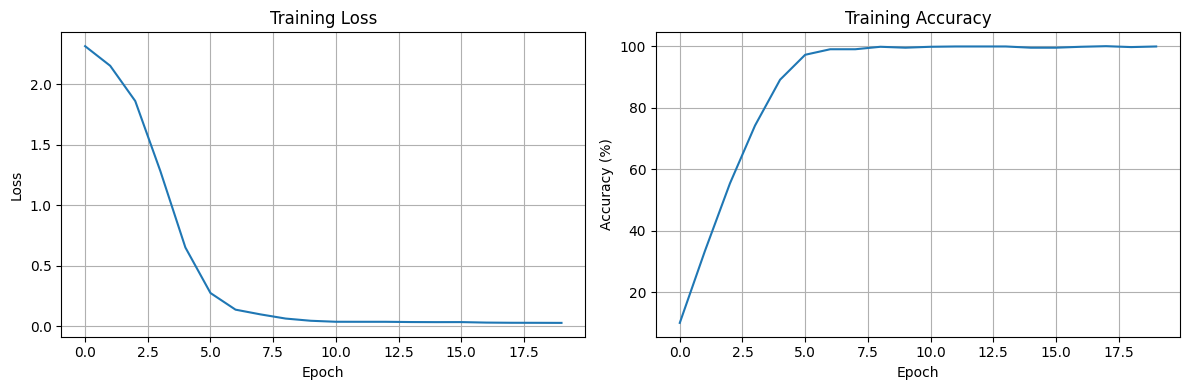

Model saved to model.pth
训练完成！


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

# 假设我们有一些训练数据（这里用随机数据演示）
# 在实际应用中，你会使用真实的数据集如 MNIST, CIFAR-10 等

# 1. 准备数据
def prepare_data():
    # 生成模拟数据：1000个样本，每个样本784维（类似28x28图像展开）
    num_samples = 1000
    input_size = 784
    num_classes = 10
    
    # 随机生成输入数据和标签
    X = torch.randn(num_samples, input_size)
    y = torch.randint(0, num_classes, (num_samples,))
    
    # 创建数据集和数据加载器
    dataset = TensorDataset(X, y)
    train_loader = DataLoader(dataset, batch_size=32, shuffle=True)
    
    return train_loader

# 2. 定义模型（使用之前定义的神经网络）
class SimpleNeuralNetwork(nn.Module):
    def __init__(self):
        super(SimpleNeuralNetwork, self).__init__()
        self.layer1 = nn.Linear(784, 128)
        self.layer2 = nn.Linear(128, 64)
        self.output_layer = nn.Linear(64, 10)
        self.dropout = nn.Dropout(0.2)  # 添加dropout防止过拟合

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = self.dropout(x)  # 在激活后添加dropout
        x = torch.relu(self.layer2(x))
        x = self.dropout(x)
        x = self.output_layer(x)
        return x

# 3. 训练函数
def train_model():
    # 准备数据
    train_loader = prepare_data()
    
    # 初始化模型
    model = SimpleNeuralNetwork()
    
    # 定义损失函数和优化器
    criterion = nn.CrossEntropyLoss()  # 交叉熵损失，适用于多分类
    optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam优化器
    
    # 学习率调度器（可选）
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
    
    # 记录训练过程中的损失和准确率
    train_losses = []
    train_accuracies = []
    
    # 训练循环
    num_epochs = 20
    
    for epoch in range(num_epochs):
        model.train()  # 设置模型为训练模式（启用dropout等）
        running_loss = 0.0
        correct = 0
        total = 0
        
        for batch_idx, (data, targets) in enumerate(train_loader):
            # 1. 梯度清零
            optimizer.zero_grad()
            
            # 2. 前向传播
            outputs = model(data)
            
            # 3. 计算损失
            loss = criterion(outputs, targets)
            
            # 4. 反向传播
            loss.backward()
            
            # 5. 参数更新
            optimizer.step()
            
            # 统计信息
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
        
        # 更新学习率
        scheduler.step()
        
        # 计算每个epoch的平均损失和准确率
        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total
        
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)
        
        print(f'Epoch [{epoch+1}/{num_epochs}], '
              f'Loss: {epoch_loss:.4f}, '
              f'Accuracy: {epoch_accuracy:.2f}%')
    
    return model, train_losses, train_accuracies

# 4. 可视化训练过程
def plot_training_curves(losses, accuracies):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    # 绘制损失曲线
    ax1.plot(losses)
    ax1.set_title('Training Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.grid(True)
    
    # 绘制准确率曲线
    ax2.plot(accuracies)
    ax2.set_title('Training Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

# 5. 模型评估
def evaluate_model(model, test_loader):
    model.eval()  # 设置模型为评估模式（禁用dropout等）
    correct = 0
    total = 0
    
    with torch.no_grad():  # 在评估时不需要计算梯度
        for data, targets in test_loader:
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    
    accuracy = 100 * correct / total
    print(f'Test Accuracy: {accuracy:.2f}%')
    return accuracy

# 6. 保存和加载模型
def save_model(model, path='model.pth'):
    torch.save(model.state_dict(), path)
    print(f'Model saved to {path}')

def load_model(model, path='model.pth'):
    model.load_state_dict(torch.load(path))
    model.eval()
    print(f'Model loaded from {path}')
    return model

# 主函数
if __name__ == "__main__":
    # 训练模型
    print("开始训练模型...")
    trained_model, losses, accuracies = train_model()
    
    # 可视化训练过程
    plot_training_curves(losses, accuracies)
    
    # 保存模型
    save_model(trained_model)
    
    print("训练完成！")

In [11]:
trained_model.layer1.weight

Parameter containing:
tensor([[-0.0221, -0.0061, -0.0067,  ..., -0.0271,  0.0013,  0.0078],
        [-0.0214, -0.0134,  0.0165,  ...,  0.0702, -0.0256,  0.0014],
        [-0.0019, -0.0070,  0.0218,  ..., -0.0388,  0.0255,  0.0079],
        ...,
        [ 0.0301,  0.0333, -0.0431,  ...,  0.0085,  0.0027,  0.0283],
        [ 0.0119,  0.0226,  0.0131,  ..., -0.0286, -0.0163,  0.0259],
        [ 0.0273, -0.0315,  0.0160,  ...,  0.0355,  0.0238,  0.0147]],
       requires_grad=True)

In [1]:
#使用transformer实例
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import numpy as np

In [2]:
t = nn.Embedding(10, 218)

In [4]:
max_len=50
d_model=16
pe = torch.zeros(max_len, d_model)
position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
div_term = torch.exp(torch.arange(0, d_model, 2).float() * 
                   (-math.log(10000.0) / d_model))

pe[:, 0::2] = torch.sin(position * div_term)
pe[:, 1::2] = torch.cos(position * div_term)

pe = pe.unsqueeze(0).transpose(0, 1)

In [16]:
fig2 = plt.figure(figsize=(12, 10))

<Figure size 1200x1000 with 0 Axes>

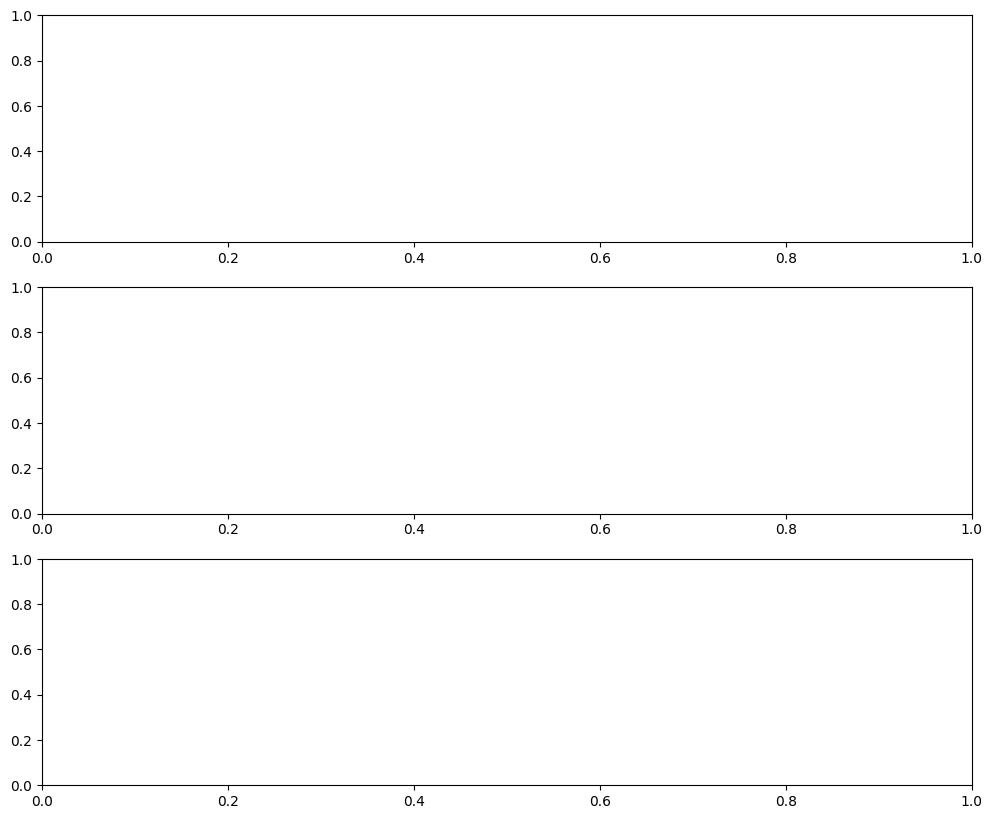

In [17]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

In [18]:
fig2

<Figure size 1200x1000 with 0 Axes>

In [21]:
type(fig)

matplotlib.figure.Figure

In [35]:
pe.transpose(0,1).numpy()[0].T

array([[ 0.00000000e+00,  8.41470957e-01,  9.09297407e-01,
         1.41120002e-01, -7.56802499e-01, -9.58924294e-01,
        -2.79415488e-01,  6.56986594e-01,  9.89358246e-01,
         4.12118495e-01, -5.44021130e-01, -9.99990225e-01,
        -5.36572933e-01,  4.20167029e-01,  9.90607381e-01,
         6.50287867e-01, -2.87903309e-01, -9.61397469e-01,
        -7.50987232e-01,  1.49877205e-01,  9.12945271e-01,
         8.36655617e-01, -8.85130931e-03, -8.46220374e-01,
        -9.05578375e-01, -1.32351756e-01,  7.62558460e-01,
         9.56375957e-01,  2.70905793e-01, -6.63633883e-01,
        -9.88031626e-01, -4.04037654e-01,  5.51426709e-01,
         9.99911845e-01,  5.29082716e-01, -4.28182662e-01,
        -9.91778851e-01, -6.43538117e-01,  2.96368569e-01,
         9.63795364e-01,  7.45113134e-01, -1.58622667e-01,
        -9.16521549e-01, -8.31774712e-01,  1.77019257e-02,
         8.50903511e-01,  9.01788354e-01,  1.23573124e-01,
        -7.68254638e-01, -9.53752637e-01],
       [ 1.00

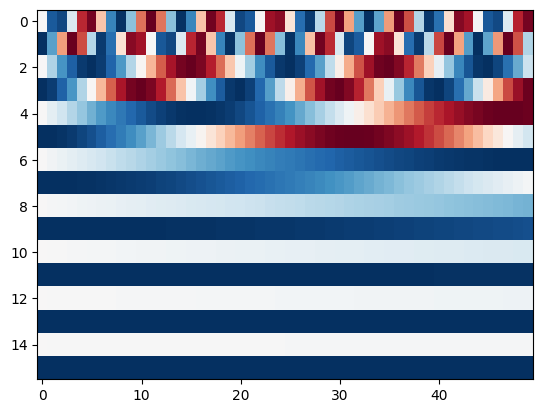

In [37]:
plt.imshow(pe.transpose(0,1).numpy()[0].T, aspect='auto', cmap='RdBu')
# plt.colorbar(im, ax=fig)

In [26]:
# 创建嵌入层：10个不同的词/类别，每个用3维向量表示
embedding_layer = nn.Embedding(num_embeddings=10, embedding_dim=3)
# 输入：整数索引张量
indices = torch.LongTensor([1, 2, 5, 7, 3])
print("输入索引:", indices)
print("输入形状:", indices.shape)  # torch.Size([5])
# 获取嵌入向量
embedded = embedding_layer(indices)
print("\n嵌入输出:", embedded)
print("输出形状:", embedded.shape)  # torch.Size([5, 3])


输入索引: tensor([1, 2, 5, 7, 3])
输入形状: torch.Size([5])

嵌入输出: tensor([[ 0.3612,  2.4402,  0.4173],
        [-0.3819,  0.1670,  0.2587],
        [ 0.9215, -1.0759,  1.3093],
        [-0.6385, -0.3204,  1.2699],
        [-0.1558,  0.4050, -0.1079]], grad_fn=<EmbeddingBackward0>)
输出形状: torch.Size([5, 3])


In [ ]:
#位置编码可视化（deepseek）
import torch
import math
import matplotlib.pyplot as plt

def visualize_positional_encoding(d_model=16, max_len=50):
    """可视化位置编码"""
    
    # 创建位置编码矩阵
    pe = torch.zeros(max_len, d_model)
    position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2).float() * 
                        (-math.log(10000.0) / d_model))
    
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    
    # 可视化
    fig, axes = plt.subplots(3, 1, figsize=(12, 10))
    
    # 1. 整体热图
    im = axes[0].imshow(pe.numpy().T, aspect='auto', cmap='RdBu')
    axes[0].set_xlabel('Position')
    axes[0].set_ylabel('Dimension')
    axes[0].set_title('Positional Encoding Heatmap')
    plt.colorbar(im, ax=axes[0])
    
    # 2. 前几个维度的变化
    for i in range(4):
        axes[1].plot(pe[:, i].numpy(), label=f'Dim {i}')
    axes[1].set_xlabel('Position')
    axes[1].set_ylabel('Encoding Value')
    axes[1].set_title('First 4 Dimensions')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    # 3. 不同位置的编码向量
    positions = [0, 10, 20, 30, 40]
    for pos in positions:
        axes[2].plot(pe[pos, :].numpy(), label=f'Pos {pos}')
    axes[2].set_xlabel('Dimension')
    axes[2].set_ylabel('Encoding Value')
    axes[2].set_title('Encoding Vectors at Different Positions')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 打印一些统计信息
    print(f"位置编码形状: {pe.shape}")
    print(f"位置编码范围: [{pe.min():.4f}, {pe.max():.4f}]")
    print(f"位置编码均值: {pe.mean():.4f}")
    print(f"位置编码标准差: {pe.std():.4f}")

visualize_positional_encoding(d_model=16, max_len=50)

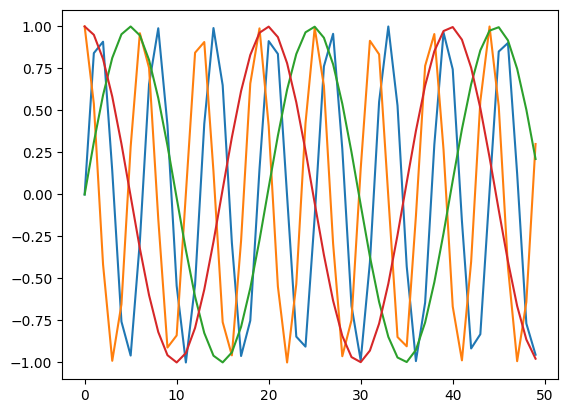

In [44]:
for i in range(4):
    plt.plot(pe[:, i].numpy(), label=f'Dim {i}')

torch.Size([16])
torch.Size([16])
torch.Size([16])
torch.Size([16])
torch.Size([16])


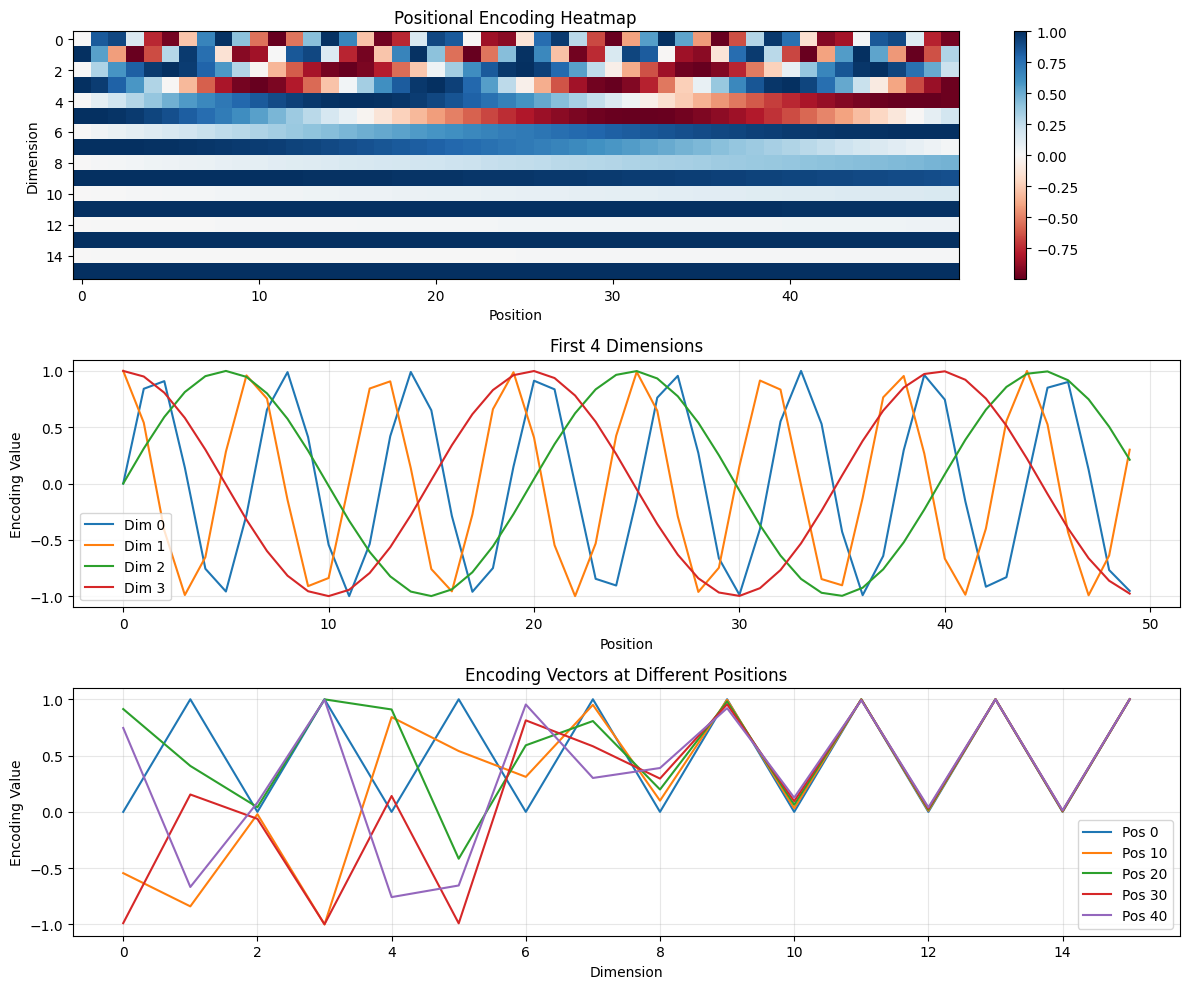

位置编码形状: torch.Size([50, 16])
位置编码范围: [-1.0000, 1.0000]
位置编码均值: 0.3552
位置编码标准差: 0.6118


In [41]:
import torch
import math
import matplotlib.pyplot as plt

d_model=16
max_len=50
# def visualize_positional_encoding(d_model=16, max_len=50):
"""可视化位置编码"""

# 创建位置编码矩阵
pe = torch.zeros(max_len, d_model)
position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
div_term = torch.exp(torch.arange(0, d_model, 2).float() * 
                    (-math.log(10000.0) / d_model))

pe[:, 0::2] = torch.sin(position * div_term)
pe[:, 1::2] = torch.cos(position * div_term)

# 可视化
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

# 1. 整体热图
im = axes[0].imshow(pe.numpy().T, aspect='auto', cmap='RdBu')
axes[0].set_xlabel('Position')
axes[0].set_ylabel('Dimension')
axes[0].set_title('Positional Encoding Heatmap')
plt.colorbar(im, ax=axes[0])

# 2. 前几个维度的变化
for i in range(4):
    axes[1].plot(pe[:, i].numpy(), label=f'Dim {i}')
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Encoding Value')
axes[1].set_title('First 4 Dimensions')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# 3. 不同位置的编码向量
positions = [0, 10, 20, 30, 40]
for pos in positions:
    print(pe[pos, :].shape)
    axes[2].plot(pe[pos, :].numpy(), label=f'Pos {pos}')
axes[2].set_xlabel('Dimension')
axes[2].set_ylabel('Encoding Value')
axes[2].set_title('Encoding Vectors at Different Positions')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 打印一些统计信息
print(f"位置编码形状: {pe.shape}")
print(f"位置编码范围: [{pe.min():.4f}, {pe.max():.4f}]")
print(f"位置编码均值: {pe.mean():.4f}")
print(f"位置编码标准差: {pe.std():.4f}")